# **3. Análisis exploratorio de datos**

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

from itertools import combinations
from collections import Counter

### **3.1 Análisis de variables continuas**

In [2]:
ruta_datos = Path.cwd().parent / 'data' / 'spotify-tracks-dataset-clean.csv'
df = pd.read_csv(ruta_datos)

print('Dimensiones del catálogo:', df.shape)

print('\nPrimeras cinco filas:')
display(df.head())

print('\nTipos de datos:')
print(df.dtypes)

print('\nValores faltantes totales:', df.isnull().sum().sum())

Dimensiones del catálogo: (89578, 20)

Primeras cinco filas:


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.210,0.000000,0.1170,0.120,76.332,4,acoustic
1,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.905,0.000071,0.1320,0.143,181.740,3,acoustic
2,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.469,0.000000,0.0829,0.167,119.949,4,acoustic
3,0IktbUcnAGrvD03AWnz3Q8,Jason Mraz;Colbie Caillat,We Sing. We Dance. We Steal Things.,Lucky,74,189613,False,0.625,0.4140,0,-8.700,1,0.0369,0.294,0.000000,0.1510,0.669,130.088,4,acoustic
4,4mzP5mHkRvGxdhdGdAH7EJ,Zack Tabudlo,Episode,Give Me Your Forever,74,244800,False,0.627,0.3630,8,-8.127,1,0.0291,0.279,0.000000,0.0928,0.301,99.905,4,acoustic



Tipos de datos:
track_id                str
artists                 str
album_name              str
track_name              str
popularity            int64
duration_ms           int64
explicit               bool
danceability        float64
energy              float64
key                   int64
loudness            float64
mode                  int64
speechiness         float64
acousticness        float64
instrumentalness    float64
liveness            float64
valence             float64
tempo               float64
time_signature        int64
track_genre             str
dtype: object

Valores faltantes totales: 0


In [3]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
popularity,89578.0,33.197816,20.587911,0.00000,19.0000,33.000000,49.00000,100.000
duration_ms,89578.0,229245.913684,111761.084308,15800.00000,173160.0000,213386.000000,264360.00000,5237295.000
danceability,89578.0,0.563160,0.175270,0.05130,0.4500,0.576000,0.69200,0.985
energy,89578.0,0.635371,0.255712,0.00002,0.4590,0.677000,0.85300,1.000
key,89578.0,5.283608,3.559180,0.00000,2.0000,5.000000,8.00000,11.000
loudness,89578.0,-8.474706,5.178135,-46.59100,-10.3070,-7.177000,-5.10400,4.532
mode,89578.0,0.636886,0.480900,0.00000,0.0000,1.000000,1.00000,1.000
speechiness,89578.0,0.087597,0.113321,0.02210,0.0360,0.049000,0.08600,0.965
acousticness,89578.0,0.327972,0.338104,0.00000,0.0171,0.187000,0.62400,0.996
instrumentalness,89578.0,0.172569,0.323103,0.00000,0.0000,0.000057,0.09390,1.000


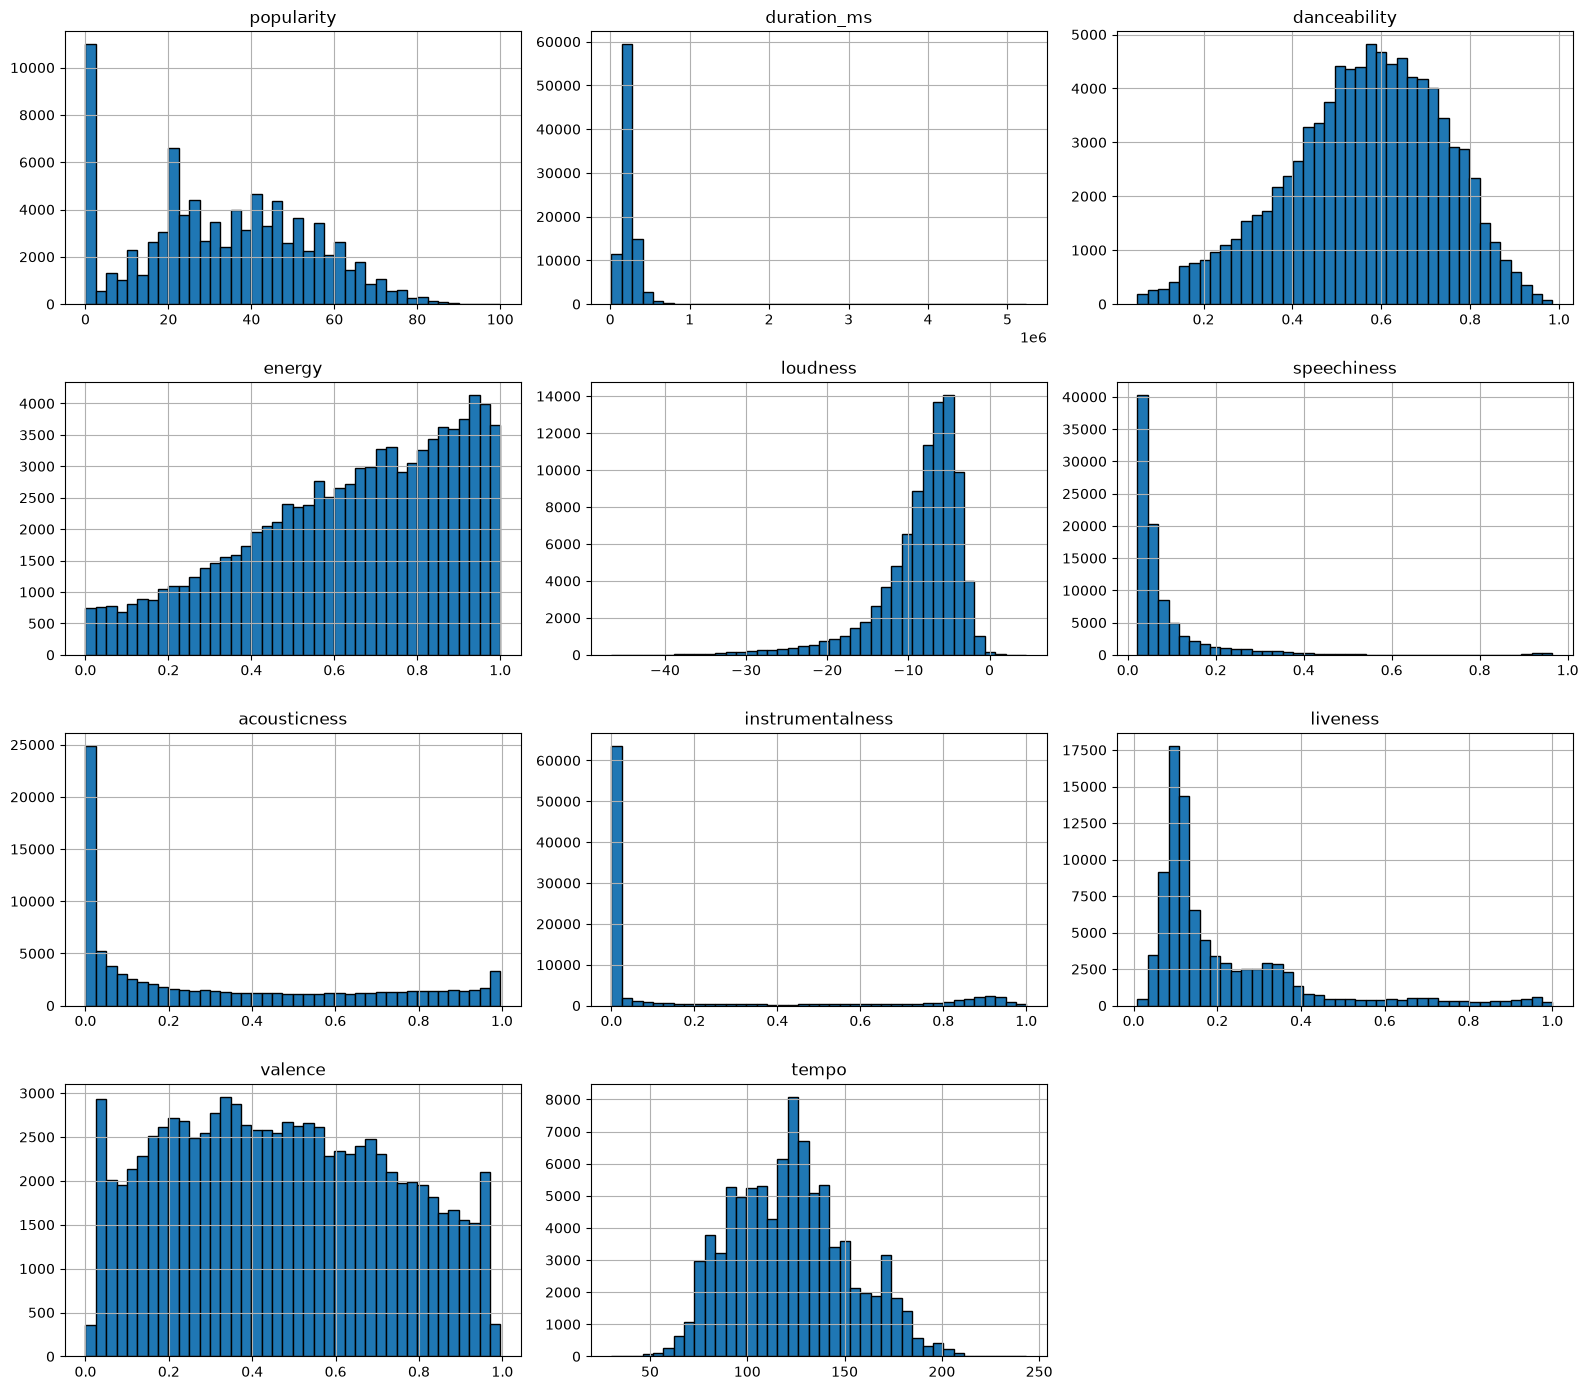

In [4]:
variables = ['popularity', 'duration_ms', 'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo'
    ]

df[variables].hist(
    bins = 40,
    figsize = (16, 14),
    edgecolor = 'black'
)

plt.tight_layout()
plt.show()

### **3.1.1 Duración (`duration_ms`)**

In [5]:
percentiles = df['duration_ms'].quantile([
    0.50,
    0.75,
    0.90,
    0.95,
    0.99,
    0.995,
    0.999,
    1.00
])

print(percentiles)

0.500     213386.000
0.750     264360.000
0.900     332767.800
0.950     394029.800
0.990     545494.990
0.995     633663.365
0.999    1068146.117
1.000    5237295.000
Name: duration_ms, dtype: float64


In [6]:
canciones_mas_largas = (
    df.nlargest(10, 'duration_ms')
    [['track_name', 'artists', 'duration_ms']]
    .copy()
)

canciones_mas_largas['duration_min'] = (canciones_mas_largas['duration_ms'] / 60000)
canciones_mas_largas

,track_name,artists,duration_ms,duration_min
47824,Unity (Voyage Mix) Pt. 1,Tale Of Us,5237295,87.288250
6828,Crossing Wires 002 - Continuous DJ Mix,Timo Maas,4789026,79.817100
16969,The Lab 03 - Continuous DJ Mix Part 1,Seth Troxler,4730302,78.838367
48045,Amnesia Ibiza Underground 10 DJ Mix,Loco Dice,4563897,76.064950
8669,House of Om - Mark Farina - Continuous Mix,Mark Farina,4447520,74.125333
8577,Live In Tokyo - Continuous Mix,Mark Farina,4339826,72.330433
8529,Greenhouse Construction,Mark Farina,4334721,72.245350
19968,"NQ State of Mind, Vol. 1 - Continuous DJ Mix",Lenzman;Dan Stezo,4246206,70.770100
64043,Ocean Waves Sounds,Ocean Sounds,4120258,68.670967
29994,Internal Flight (Remastered),Estas Tonne,3876276,64.604600


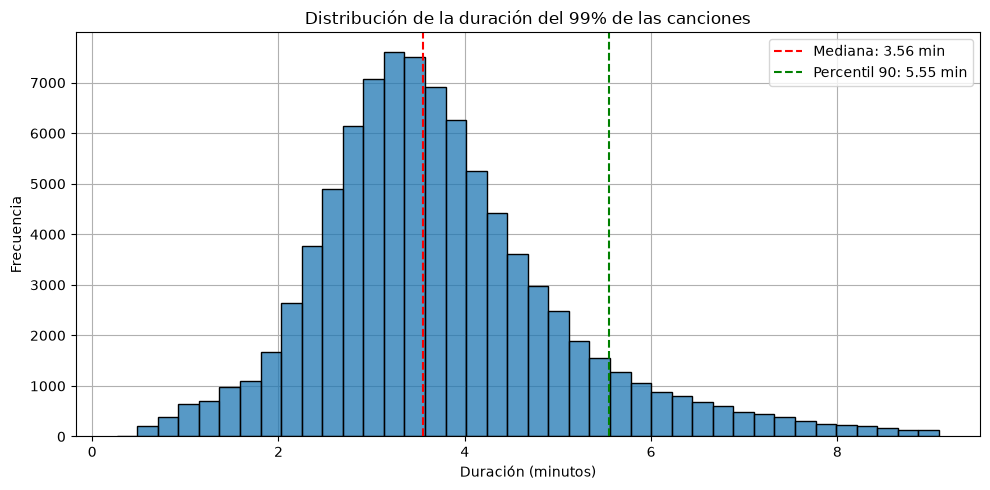

In [7]:
# Calculamos el percentil 99
limite_p99 = df['duration_ms'].quantile(0.99)

# Seleccionamos las canciones que no superan ese límite
duraciones = df.loc[
    df['duration_ms'] <= limite_p99,
    'duration_ms'
] / 60000

# Calculamos algunas referencias
mediana = df['duration_ms'].median() / 60000
percentil_90 = df['duration_ms'].quantile(0.90) / 60000

# Construimos el histograma
plt.figure(figsize=(10, 5))

sns.histplot(duraciones, bins = 40, edgecolor = 'black')

plt.axvline(
    mediana,
    color = 'red',
    linestyle = '--',
    label = f'Mediana: {mediana:.2f} min'
)

plt.axvline(
    percentil_90,
    color = 'green',
    linestyle = '--',
    label = f'Percentil 90: {percentil_90:.2f} min'
)

plt.gca().set_axisbelow(True)
plt.title('Distribución de la duración del 99% de las canciones')
plt.xlabel('Duración (minutos)')
plt.ylabel('Frecuencia')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### **3.1.2 Boxplots**

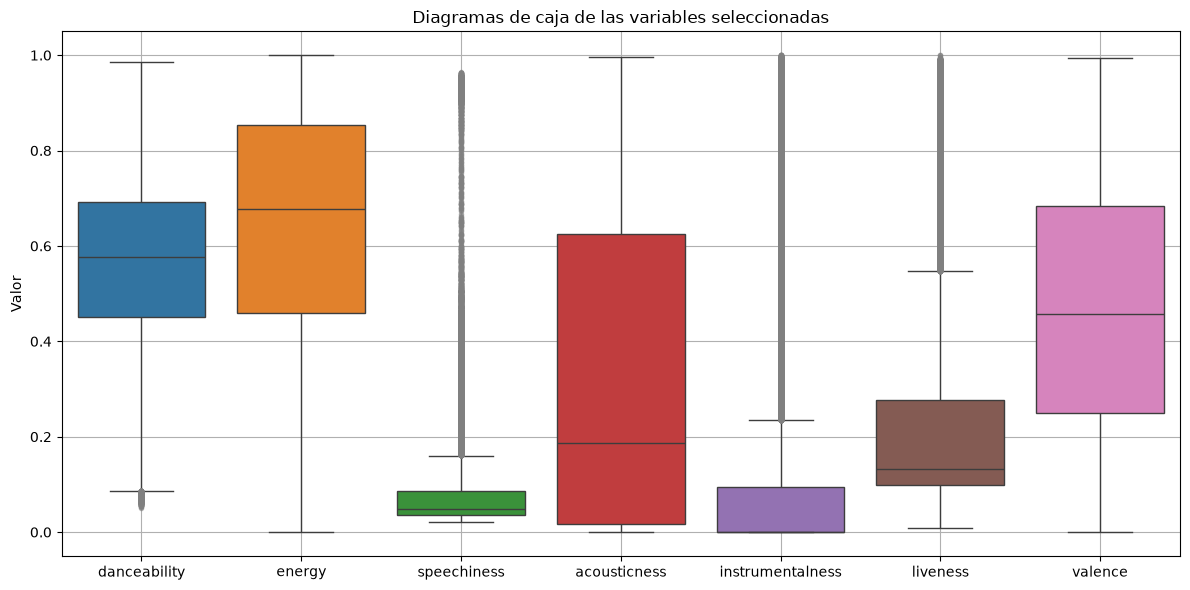

In [8]:
variables_boxplot = [
    'danceability',
    'energy',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence'
]

plt.figure(figsize = (12, 6))
sns.boxplot(data = df[variables_boxplot], flierprops = {
        'marker': 'o',
        'markersize': 3,
        'markerfacecolor': 'gray',
        'markeredgecolor': 'gray',
        'alpha': 0.5
    })

plt.title('Diagramas de caja de las variables seleccionadas')
plt.ylabel('Valor')
plt.grid()
plt.tight_layout()
plt.show()

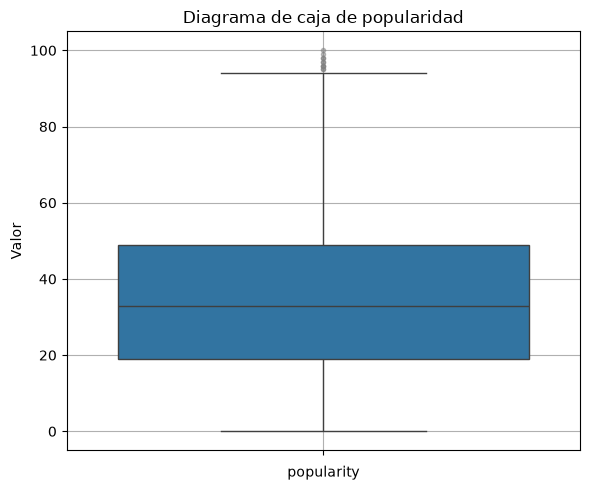

In [9]:
plt.figure(figsize = (6, 5))
sns.boxplot(data = df['popularity'], flierprops = {
        'marker': 'o',
        'markersize': 3,
        'markerfacecolor': 'gray',
        'markeredgecolor': 'gray',
        'alpha': 0.5
    })

plt.title('Diagrama de caja de popularidad')
plt.xlabel('popularity')
plt.ylabel('Valor')
plt.grid()
plt.tight_layout()
plt.show()

In [10]:
variables_boxplot = [
    'popularity',
    'danceability',
    'energy',
    'speechiness',
    'acousticness',
    'instrumentalness',
    'liveness',
    'valence'
]

resultados_boxplot = []
for variable in variables_boxplot:

    Q1 = df[variable].quantile(0.25)
    Q2 = df[variable].median()
    Q3 = df[variable].quantile(0.75)
    RIQ = Q3 - Q1

    limite_inferior = Q1 - 1.5 * RIQ
    limite_superior = Q3 + 1.5 * RIQ

    atipicos = df[(df[variable] < limite_inferior) | (df[variable] > limite_superior)]

    resultados_boxplot.append({
        'variable': variable,
        'Q1': Q1,
        'Mediana': Q2,
        'Q3': Q3,
        'RIQ': RIQ,
        'Limite inferior': limite_inferior,
        'Limite superior': limite_superior,
        'Cantidad de atipicos': len(atipicos),
        'Porcentaje de atipicos': len(atipicos) / len(df) * 100
    })

tabla_boxplot = pd.DataFrame(resultados_boxplot)
tabla_boxplot.round(5)

,variable,Q1,Mediana,Q3,RIQ,Limite inferior,Limite superior,Cantidad de atipicos,Porcentaje de atipicos
0,popularity,19.0000,33.00000,49.0000,30.0000,-26.00000,94.00000,11,0.01228
1,danceability,0.4500,0.57600,0.6920,0.2420,0.08700,1.05500,317,0.35388
2,energy,0.4590,0.67700,0.8530,0.3940,-0.13200,1.44400,0,0.00000
3,speechiness,0.0360,0.04900,0.0860,0.0500,-0.03900,0.16100,10644,11.88238
4,acousticness,0.0171,0.18700,0.6240,0.6069,-0.89325,1.53435,0,0.00000
5,instrumentalness,0.0000,0.00006,0.0939,0.0939,-0.14085,0.23475,19616,21.89823
6,liveness,0.0982,0.13200,0.2780,0.1798,-0.17150,0.54770,6969,7.77981
7,valence,0.2500,0.45800,0.6830,0.4330,-0.39950,1.33250,0,0.00000


### **3.2 Análisis de variables categóricas y discretas**

In [11]:
variables_categoricas = ['key', 'mode', 'time_signature', 'explicit']

for variable in variables_categoricas:
    print(f'\nDistribución de {variable}:')

    frecuencias = df[variable].value_counts().sort_index()

    porcentajes = (
        df[variable]
        .value_counts(normalize=True)
        .sort_index() * 100
    )

    tabla = pd.DataFrame({
        'Frecuencia': frecuencias,
        'Porcentaje (%)': porcentajes
    })

    display(tabla.round(2))


Distribución de key:


,Frecuencia,Porcentaje (%)
key,,
0,10335,11.54
1,8547,9.54
2,9307,10.39
3,2763,3.08
4,7129,7.96
5,7302,8.15
6,6131,6.84
7,10542,11.77
8,5557,6.20



Distribución de mode:


,Frecuencia,Porcentaje (%)
mode,,
0,32527,36.31
1,57051,63.69



Distribución de time_signature:


,Frecuencia,Porcentaje (%)
time_signature,,
1,846,0.94
3,7604,8.49
4,79543,88.80
5,1585,1.77



Distribución de explicit:


,Frecuencia,Porcentaje (%)
explicit,,
False,81874,91.4
True,7704,8.6


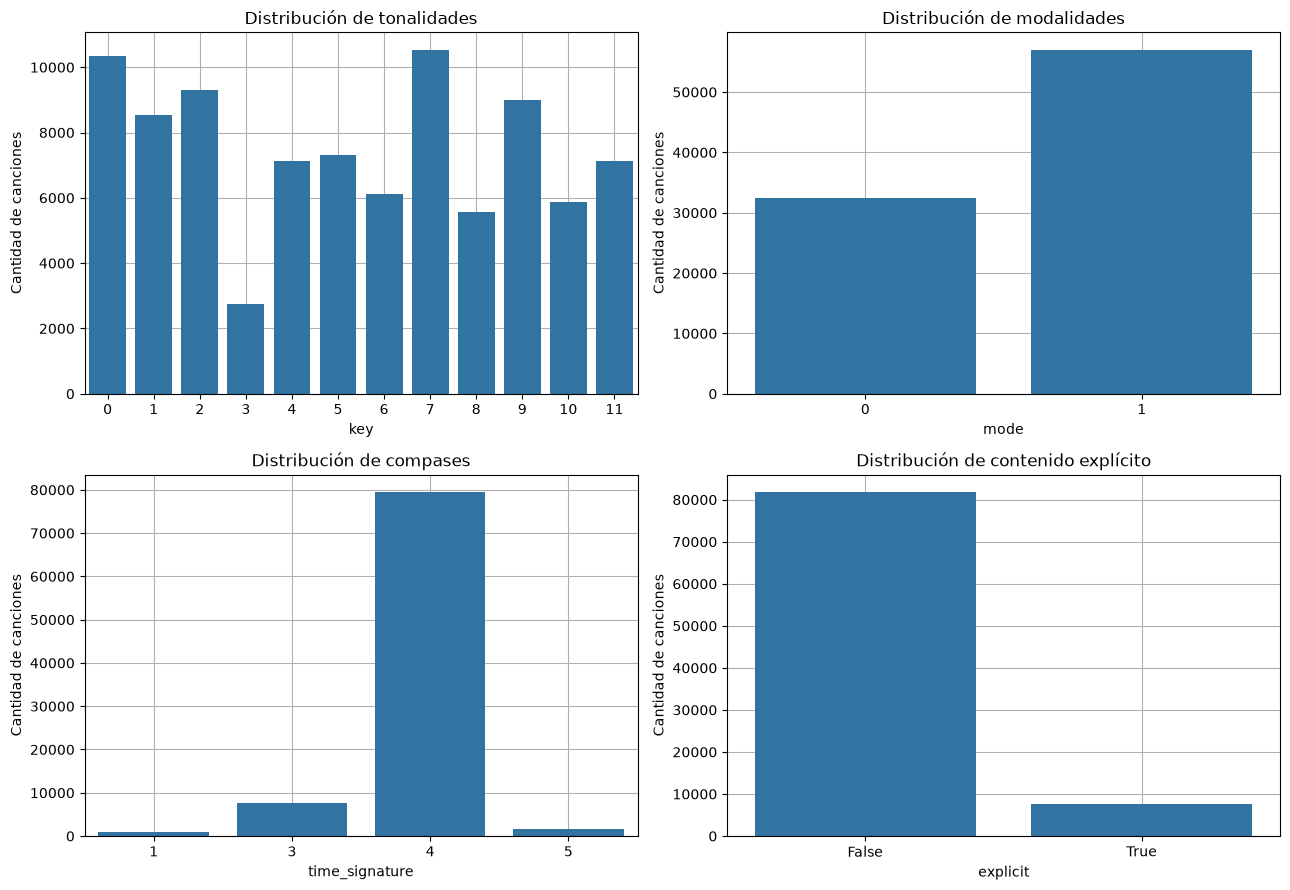

In [12]:
fig, axes = plt.subplots(2, 2, figsize = (13, 9))

variables = ['key', 'mode', 'time_signature', 'explicit']

titulos = [
    'Distribución de tonalidades',
    'Distribución de modalidades',
    'Distribución de compases',
    'Distribución de contenido explícito'
]

for ax, variable, titulo in zip(axes.flatten(), variables, titulos):
    orden = sorted(df[variable].unique())

    sns.countplot(data = df, x = variable, order = orden, ax = ax)

    ax.set_axisbelow(True)
    ax.set_title(titulo)
    ax.set_xlabel(variable)
    ax.set_ylabel('Cantidad de canciones')
    ax.grid()

plt.tight_layout()
plt.show()

### **3.3 Análisis de los géneros musicales**

In [13]:
# Cantidad de registros con uno o más géneros
generos_por_cancion = df['track_genre'].str.split(';')

cantidad_generos = generos_por_cancion.str.len()

print('Distribución de la cantidad de géneros por canción:')
display(cantidad_generos.value_counts().sort_index())

print('\nNúmero máximo de géneros asociados a una canción:', cantidad_generos.max())

Distribución de la cantidad de géneros por canción:


track_genre
1    73280
2    11423
3     2955
4     1361
5      431
6      104
7       21
8        2
9        1
Name: count, dtype: int64


Número máximo de géneros asociados a una canción: 9


In [14]:
# Separar los géneros individuales
generos_individuales = df['track_genre'].str.split(';').explode()

# Contar las apariciones de cada género
frecuencia_generos = generos_individuales.value_counts()

# Crear una tabla con frecuencias absolutas y relativas
tabla_generos = pd.DataFrame({
    'canciones': frecuencia_generos,
    'porcentaje': frecuencia_generos / len(df) * 100
})

print('Número de géneros diferentes:', len(tabla_generos))
display(tabla_generos.round(2))

Número de géneros diferentes: 114


,canciones,porcentaje
track_genre,,
acoustic,1000,1.12
british,1000,1.12
country,1000,1.12
disco,1000,1.12
electronic,1000,1.12
...,...,...
dance,965,1.08
german,963,1.08
classical,933,1.04


In [15]:
print('15 géneros más frecuentes:')
display(tabla_generos.head(15))

print('\n15 géneros menos frecuentes:')
display(tabla_generos.tail(15))

print('\nEstadísticas generales de las frecuencias de géneros:')
display(frecuencia_generos.describe())

15 géneros más frecuentes:


,canciones,porcentaje
track_genre,,
acoustic,1000,1.116346
british,1000,1.116346
country,1000,1.116346
disco,1000,1.116346
electronic,1000,1.116346
emo,1000,1.116346
funk,1000,1.116346
garage,1000,1.116346
indie-pop,1000,1.116346



15 géneros menos frecuentes:


,canciones,porcentaje
track_genre,,
edm,993,1.108531
j-dance,993,1.108531
latino,993,1.108531
pop,993,1.108531
hip-hop,991,1.106298
kids,991,1.106298
latin,990,1.105182
opera,989,1.104066
iranian,984,1.098484



Estadísticas generales de las frecuencias de géneros:


count     114.000000
mean      994.614035
std        17.298784
min       862.000000
25%       997.000000
50%       999.000000
75%      1000.000000
max      1000.000000
Name: count, dtype: float64

In [16]:
generos_con_1000 = (frecuencia_generos == 1000).sum()

print(f'Géneros con exactamente 1000 canciones: {generos_con_1000} de {len(frecuencia_generos)}')

Géneros con exactamente 1000 canciones: 32 de 114


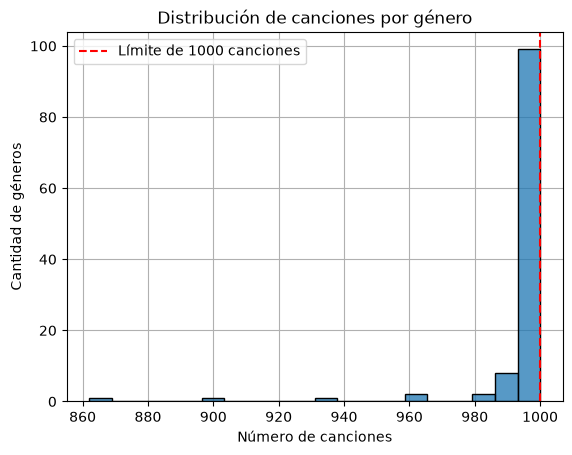

In [17]:
# Histograma de frecuencias por género
sns.histplot(frecuencia_generos, bins = 20, edgecolor = 'black')

plt.axvline(1000, color = 'red', linestyle = '--', label = 'Límite de 1000 canciones')

plt.gca().set_axisbelow(True)
plt.title('Distribución de canciones por género')
plt.xlabel('Número de canciones')
plt.ylabel('Cantidad de géneros')
plt.legend()
plt.grid()

plt.show()

### **3.3.1 Asociación entre géneros musicales**

In [18]:
# Contador de pares de géneros
pares_generos = Counter()

# Recorrer las canciones
for lista in df['track_genre'].str.split(';'):

    # Separar, limpiar y evitar posibles repeticiones
    generos = sorted(set(g.strip() for g in lista))

    # Generar todas las combinaciones de dos géneros
    pares = combinations(generos, 2)

    # Contabilizar las combinaciones
    pares_generos.update(pares)

print('Número de combinaciones diferentes:', len(pares_generos))
print('Número total de asociaciones contabilizadas:', sum(pares_generos.values()))

Número de combinaciones diferentes: 1123
Número total de asociaciones contabilizadas: 34857


In [19]:
# Convertir las combinaciones en una tabla
tabla_pares = pd.DataFrame(pares_generos.items(), columns = ['combinacion', 'frecuencia'])

# Ordenar de mayor a menor frecuencia
tabla_pares = tabla_pares.sort_values(
    by = 'frecuencia',
    ascending = False
).reset_index(drop = True)

# Mostrar las 20 combinaciones más frecuentes
display(tabla_pares.head(20))

,combinacion,frecuencia
0,"(singer-songwriter, songwriter)",1000
1,"(reggae, reggaeton)",804
2,"(latino, reggaeton)",738
3,"(dub, dubstep)",727
4,"(punk, punk-rock)",628
5,"(edm, house)",624
6,"(latino, reggae)",616
7,"(alt-rock, alternative)",592
8,"(latin, latino)",588
9,"(indie, indie-pop)",579


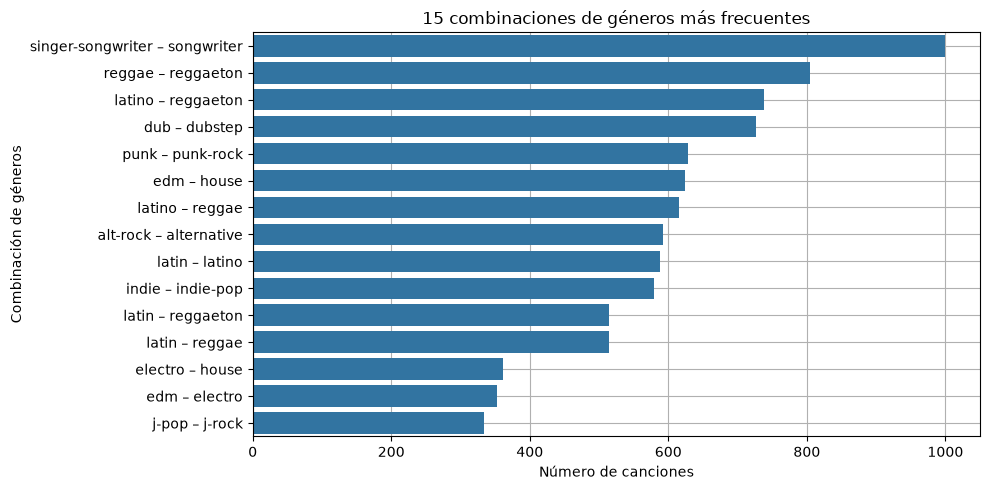

In [20]:
# Seleccionar las 15 combinaciones más frecuentes
top_pares = tabla_pares.head(15).copy()

# Convertir las tuplas en etiquetas legibles
top_pares['etiqueta'] = top_pares['combinacion'].apply(
    lambda par: ' – '.join(par)
)

# Ordenar para que la combinación más frecuente aparezca arriba
top_pares = top_pares.sort_values(by='frecuencia', ascending = False)

plt.figure(figsize = (10, 5))

sns.barplot(data = top_pares, x = 'frecuencia', y = 'etiqueta')

plt.gca().set_axisbelow(True)
plt.title('15 combinaciones de géneros más frecuentes')
plt.xlabel('Número de canciones')
plt.ylabel('Combinación de géneros')
plt.grid()

plt.tight_layout()
plt.show()

In [21]:
# Crear una lista para almacenar los resultados
resultados_jaccard = []

# Recorrer todas las combinaciones
for (genero_A, genero_B), interseccion in pares_generos.items():

    # Frecuencia individual de cada género
    frecuencia_A = frecuencia_generos[genero_A]
    frecuencia_B = frecuencia_generos[genero_B]

    # Unión de ambos conjuntos
    union = frecuencia_A + frecuencia_B - interseccion

    # Índice de Jaccard
    jaccard = interseccion / union

    resultados_jaccard.append({
        'genero_A': genero_A,
        'genero_B': genero_B,
        'interseccion': interseccion,
        'union': union,
        'jaccard': jaccard
    })

# Convertir los resultados en un DataFrame
tabla_jaccard = pd.DataFrame(resultados_jaccard)
tabla_jaccard = tabla_jaccard.sort_values(by = 'jaccard', ascending = False).reset_index(drop = True)

display(tabla_jaccard.head(20).round(4))

,genero_A,genero_B,interseccion,union,jaccard
0,singer-songwriter,songwriter,1000,1000,1.0000
1,reggae,reggaeton,804,1196,0.6722
2,latino,reggaeton,738,1255,0.5880
3,dub,dubstep,727,1271,0.5720
4,punk,punk-rock,628,1371,0.4581
5,edm,house,624,1368,0.4561
6,latino,reggae,616,1377,0.4473
7,latin,latino,588,1395,0.4215
8,alt-rock,alternative,592,1405,0.4214
9,indie,indie-pop,579,1418,0.4083


In [22]:
print('\nDistribución general del índice de Jaccard:')
display(tabla_jaccard['jaccard'].describe().round(4))


Distribución general del índice de Jaccard:


count    1123.0000
mean        0.0182
std         0.0601
min         0.0005
25%         0.0010
50%         0.0035
75%         0.0122
max         1.0000
Name: jaccard, dtype: float64

### **3.4 Análisis de popularidad**

In [23]:
df['popularity'].describe()

count    89578.000000
mean        33.197816
std         20.587911
min          0.000000
25%         19.000000
50%         33.000000
75%         49.000000
max        100.000000
Name: popularity, dtype: float64

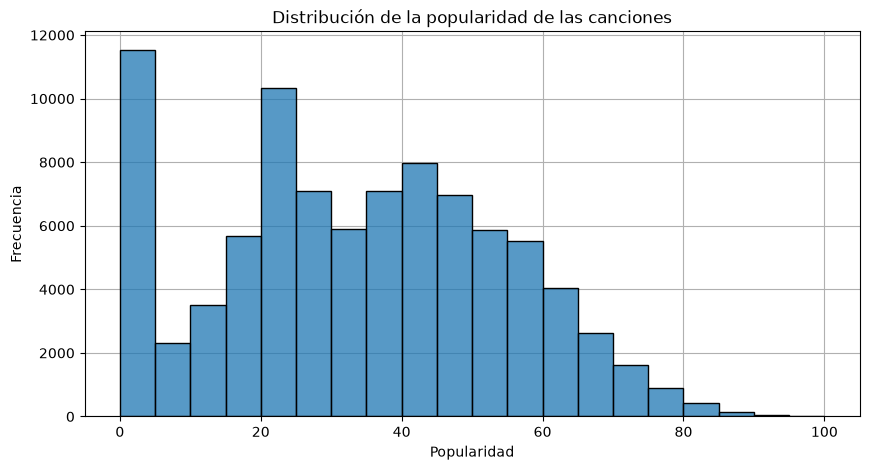

In [24]:
plt.figure(figsize = (10, 5))

sns.histplot(data = df, x = 'popularity', bins = 20)

plt.gca().set_axisbelow(True)
plt.title('Distribución de la popularidad de las canciones')
plt.xlabel('Popularidad')
plt.ylabel('Frecuencia')
plt.grid()

plt.show()

In [25]:
canciones_cero = (df['popularity'] == 0).sum()
porcentaje_cero = canciones_cero / len(df) * 100

print(f'Canciones con popularidad cero: {canciones_cero}')
print(f'Porcentaje del conjunto: {porcentaje_cero:.2f}%')

Canciones con popularidad cero: 9343
Porcentaje del conjunto: 10.43%


In [26]:
df.loc[df['popularity'] > 0, 'popularity'].describe()

count    80235.000000
mean        37.063551
std         18.164247
min          1.000000
25%         22.000000
50%         37.000000
75%         50.000000
max        100.000000
Name: popularity, dtype: float64

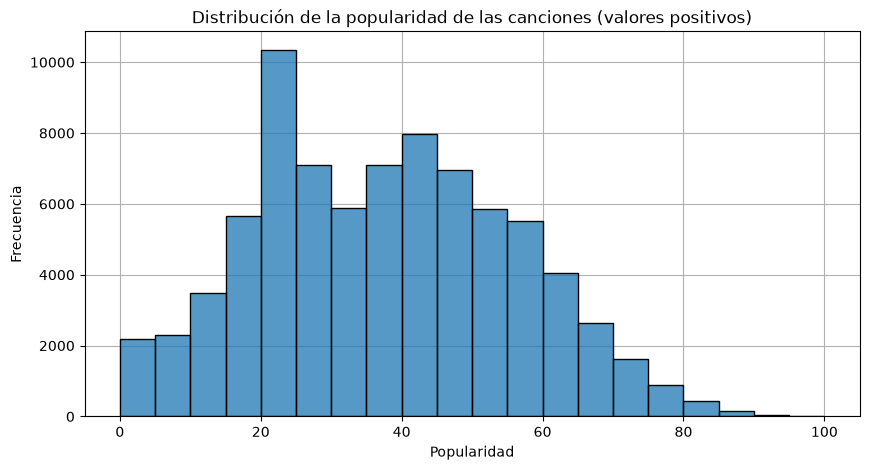

In [27]:
plt.figure(figsize = (10, 5))

sns.histplot(data = df[df['popularity'] > 0], x = 'popularity', bins = np.arange(0, 105, 5))

plt.gca().set_axisbelow(True)
plt.title('Distribución de la popularidad de las canciones (valores positivos)')
plt.xlabel('Popularidad')
plt.ylabel('Frecuencia')
plt.grid()

plt.show()

In [28]:
canciones_mas_populares = df.nlargest(10, 'popularity')[['track_name', 'artists', 'track_genre', 'popularity']]
canciones_mas_populares

,track_name,artists,track_genre,popularity
77840,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,dance;pop,100
34894,"Quevedo: Bzrp Music Sessions, Vol. 52",Bizarrap;Quevedo,hip-hop,99
77847,I'm Good (Blue),David Guetta;Bebe Rexha,dance;edm;pop,98
85881,La Bachata,Manuel Turizo,latin;latino;reggae;reggaeton,98
85883,Me Porto Bonito,Bad Bunny;Chencho Corleone,latin;latino;reggae;reggaeton,97
85884,Tití Me Preguntó,Bad Bunny,latin;latino;reggae;reggaeton,97
77839,Under The Influence,Chris Brown,dance;pop,96
85974,Efecto,Bad Bunny,latin;latino;reggae;reggaeton,96
87446,I Ain't Worried,OneRepublic,piano;pop;rock,96
53181,As It Was,Harry Styles,pop,95


In [29]:
canciones_menos_populares = df[df['popularity'] > 0].nsmallest(
    10, 'popularity'
)[['track_name', 'artists', 'track_genre', 'popularity']]

canciones_menos_populares

,track_name,artists,track_genre,popularity
1938,Placeholder,Oliver Tree,alternative,1
1944,Howl,Florence + The Machine,alternative,1
1945,Seven Devils,Florence + The Machine,alternative,1
1946,Howl,Florence + The Machine,alternative,1
1947,Girl With One Eye,Florence + The Machine,alternative,1
1949,Howl,Florence + The Machine,alternative,1
1965,god has a sense of humor,GAYLE,alternative,1
1970,abcdefu,GAYLE,alternative,1
2000,Living Hell,Bella Poarch,alternative,1
2002,Living Hell,Bella Poarch,alternative,1


In [30]:
frecuencia_popularidad = df['popularity'].value_counts().sort_index()

print('Valores de popularidad más bajos:')
print(frecuencia_popularidad.head(6))

print('\nValores de popularidad más altos:')
print(frecuencia_popularidad.tail(6))

Valores de popularidad más bajos:
popularity
0    9343
1    1137
2     505
3     309
4     242
5     510
Name: count, dtype: int64

Valores de popularidad más altos:
popularity
95     2
96     3
97     2
98     2
99     1
100    1
Name: count, dtype: int64


### **3.4.1 Relación entre popularidad y características de audio**

In [31]:
caracteristicas_audio = ['danceability', 'energy', 'loudness', 'speechiness', 'acousticness', 'instrumentalness',
    'liveness', 'valence', 'tempo'
]

correlaciones = df[caracteristicas_audio + ['popularity']].corr()
correlacion_popularidad = correlaciones['popularity'].drop('popularity')

correlacion_popularidad = correlacion_popularidad.reindex(
    correlacion_popularidad.abs().sort_values(ascending = False).index
)

correlacion_popularidad

instrumentalness   -0.128613
loudness            0.073274
danceability        0.065993
speechiness        -0.046926
acousticness       -0.039004
energy              0.014395
liveness           -0.014335
valence            -0.010956
tempo               0.008812
Name: popularity, dtype: float64

### **3.4.2 Popularidad promedio por género**

In [32]:
df_generos = df.assign(track_genre = df['track_genre'].str.split(';')).explode('track_genre')

df_generos[['track_name', 'track_genre', 'popularity']]

,track_name,track_genre,popularity
0,To Begin Again,acoustic,57
1,Can't Help Falling In Love,acoustic,71
2,Hold On,acoustic,82
3,Lucky,acoustic,74
4,Give Me Your Forever,acoustic,74
...,...,...,...
89575,Capumcap,trip-hop,27
89576,Follow You Anywhere,techno,45
89576,Follow You Anywhere,trance,45
89577,Imagineering,techno,47


In [33]:
estadisticas_generos = df_generos.groupby('track_genre')['popularity'].agg(
    cantidad = 'count',
    media = 'mean',
    mediana = 'median',
    desviacion = 'std'
).sort_values('media', ascending = False)

estadisticas_generos

,cantidad,media,mediana,desviacion
track_genre,,,,
pop-film,999,59.280280,60.0,10.254161
k-pop,998,56.969940,60.0,16.845963
chill,999,53.714715,57.0,14.838668
sad,1000,52.418000,54.0,11.502764
grunge,999,49.583584,55.0,18.491962
...,...,...,...,...
chicago-house,998,12.333667,10.0,9.587997
detroit-techno,998,11.183367,8.0,8.955448
latin,990,8.427273,0.0,22.067097


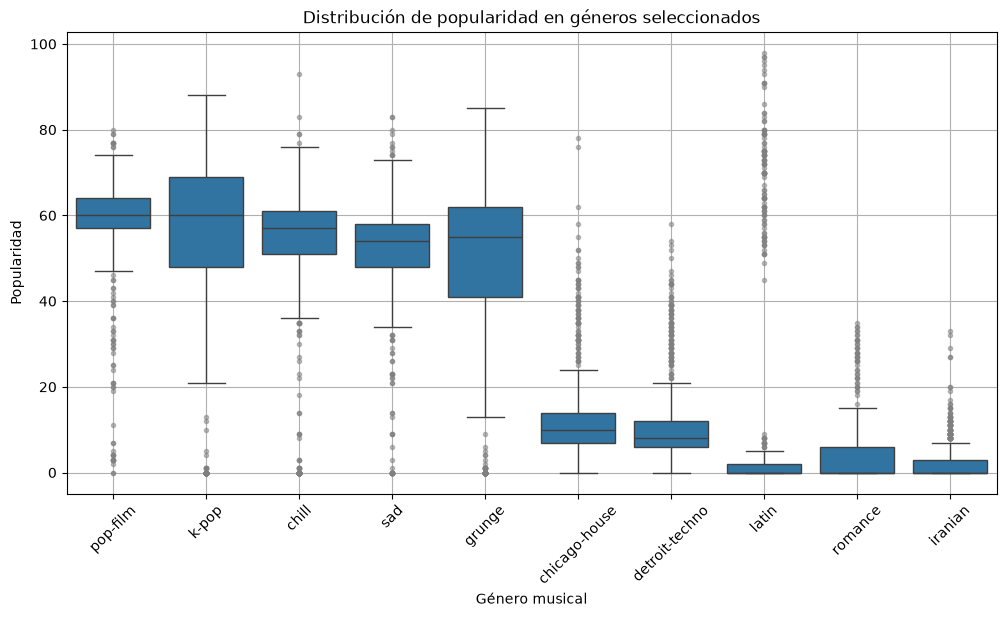

In [34]:
generos_seleccionados = (
    estadisticas_generos.head(5).index.tolist()
    + estadisticas_generos.tail(5).index.tolist()
)

plt.figure(figsize = (12, 6))

sns.boxplot(
    data = df_generos[df_generos['track_genre'].isin(generos_seleccionados)],
    x = 'track_genre',
    y = 'popularity',
    order = generos_seleccionados,
    flierprops = {
        'marker': 'o',
        'markersize': 3,
        'markerfacecolor': 'gray',
        'markeredgecolor': 'gray',
        'alpha': 0.5
    }
)

plt.title('Distribución de popularidad en géneros seleccionados')
plt.xlabel('Género musical')
plt.ylabel('Popularidad')
plt.xticks(rotation = 45)
plt.grid()

plt.show()

In [35]:
porcentaje_ceros_genero = df_generos.groupby('track_genre').agg(
    cantidad = ('popularity', 'count'),
    canciones_cero = ('popularity', lambda x: (x == 0).sum())
)

porcentaje_ceros_genero['porcentaje_cero'] = (
    porcentaje_ceros_genero['canciones_cero'] / porcentaje_ceros_genero['cantidad'] * 100
)

porcentaje_ceros_genero = porcentaje_ceros_genero.sort_values('porcentaje_cero', ascending = False)

porcentaje_ceros_genero

,cantidad,canciones_cero,porcentaje_cero
track_genre,,,
jazz,998,680,68.136273
iranian,984,644,65.447154
romance,903,555,61.461794
soul,999,608,60.860861
country,1000,583,58.300000
...,...,...,...
detroit-techno,998,1,0.100200
sertanejo,1000,1,0.100000
comedy,996,0,0.000000


### **3.5 Análisis de las relaciones entre características de audio**

In [36]:
matriz_correlacion = df[caracteristicas_audio].corr(method='pearson')

matriz_correlacion

,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
danceability,1.000000,0.134542,0.261972,0.106209,-0.176077,-0.188789,-0.127067,0.488319,-0.044972
energy,0.134542,1.000000,0.759191,0.139305,-0.735073,-0.177458,0.194201,0.251843,0.249105
loudness,0.261972,0.759191,1.000000,0.052264,-0.584619,-0.433561,0.081360,0.284259,0.215135
speechiness,0.106209,0.139305,0.052264,1.000000,0.005821,-0.098025,0.227697,0.030617,-0.001473
acousticness,-0.176077,-0.735073,-0.584619,0.005821,1.000000,0.095142,-0.019276,-0.102626,-0.220192
instrumentalness,-0.188789,-0.177458,-0.433561,-0.098025,0.095142,1.000000,-0.091410,-0.328080,-0.047199
liveness,-0.127067,0.194201,0.081360,0.227697,-0.019276,-0.091410,1.000000,0.016225,0.002592
valence,0.488319,0.251843,0.284259,0.030617,-0.102626,-0.328080,0.016225,1.000000,0.079291
tempo,-0.044972,0.249105,0.215135,-0.001473,-0.220192,-0.047199,0.002592,0.079291,1.000000


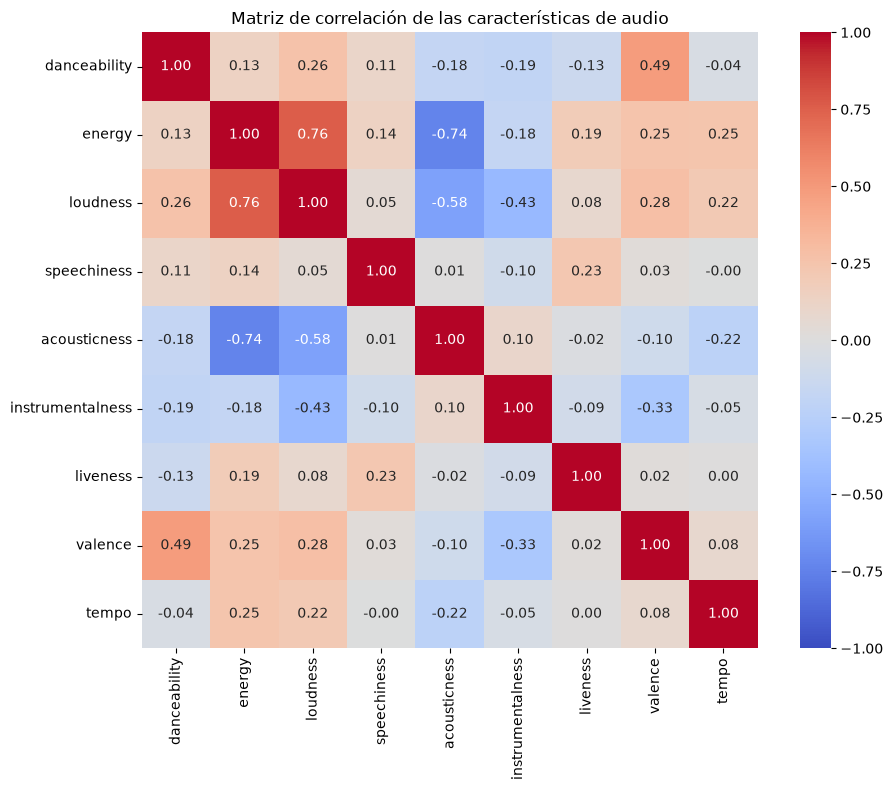

In [37]:
plt.figure(figsize = (10, 8))

sns.heatmap(
    matriz_correlacion,
    annot = True,
    cmap = 'coolwarm',
    fmt = '.2f',
    vmin = -1,
    vmax = 1,
    center = 0,
    square = True
)

plt.title('Matriz de correlación de las características de audio')
plt.tight_layout()
plt.show()

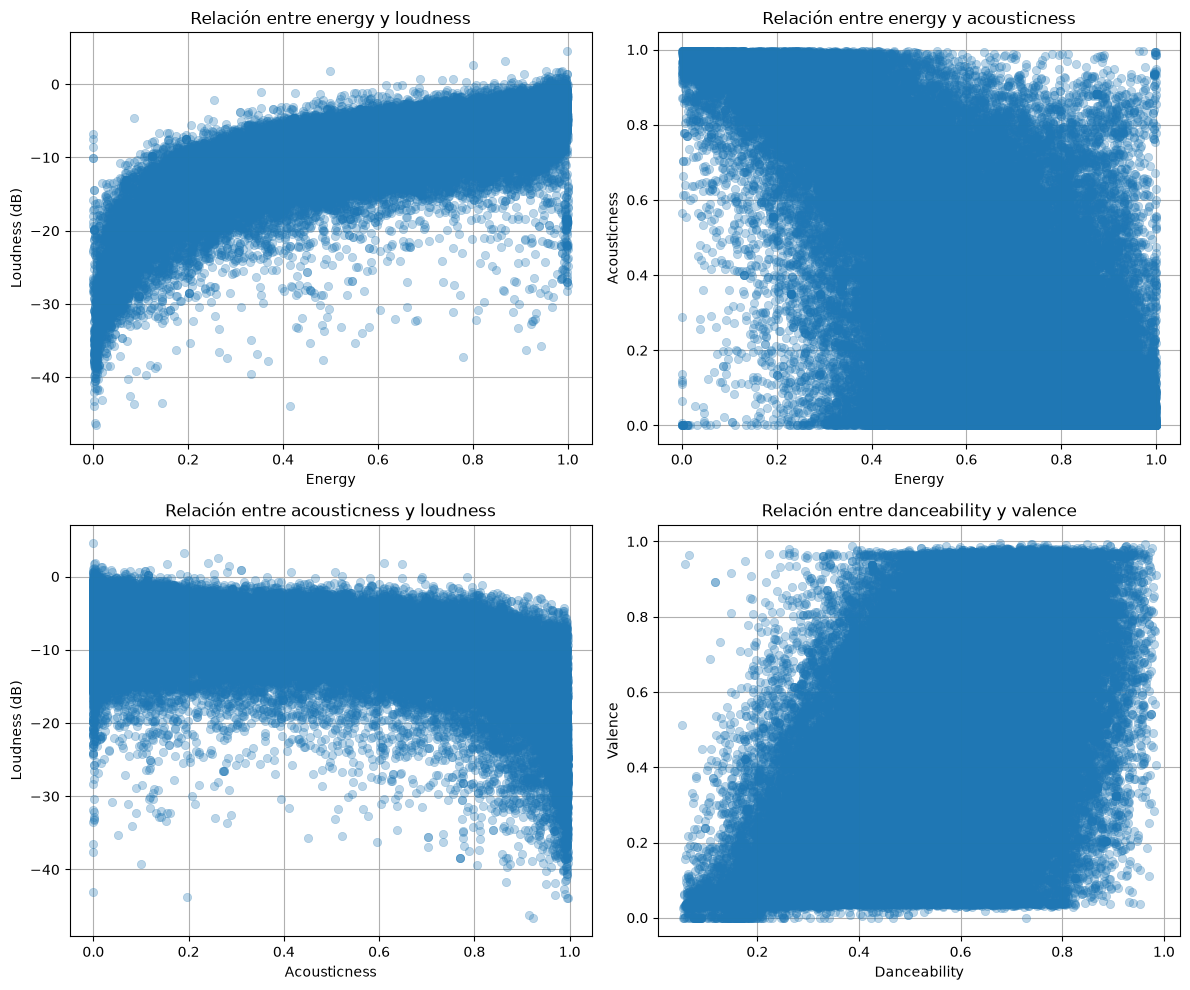

In [38]:
fig, axs = plt.subplots(2, 2, figsize = (12, 10))

g0 = axs.ravel()[0]
g1 = axs.ravel()[1]
g2 = axs.ravel()[2]
g3 = axs.ravel()[3]

sns.scatterplot(data = df, x = 'energy', y = 'loudness', alpha = 0.3, edgecolor = None, ax = g0)
g0.set_axisbelow(True)
g0.set_title('Relación entre energy y loudness')
g0.set_xlabel('Energy')
g0.set_ylabel('Loudness (dB)')
g0.grid()

sns.scatterplot(data = df, x = 'energy', y = 'acousticness', alpha = 0.3, edgecolor = None, ax = g1)
g1.set_axisbelow(True)
g1.set_title('Relación entre energy y acousticness')
g1.set_xlabel('Energy')
g1.set_ylabel('Acousticness')
g1.grid()

sns.scatterplot(data = df, x = 'acousticness', y = 'loudness', alpha = 0.3, edgecolor = None, ax = g2)
g2.set_axisbelow(True)
g2.set_title('Relación entre acousticness y loudness')
g2.set_xlabel('Acousticness')
g2.set_ylabel('Loudness (dB)')
g2.grid()

sns.scatterplot(data = df, x = 'danceability', y = 'valence', alpha = 0.3, edgecolor = None, ax = g3)
g3.set_axisbelow(True)
g3.set_title('Relación entre danceability y valence')
g3.set_xlabel('Danceability')
g3.set_ylabel('Valence')
g3.grid()

plt.tight_layout()
plt.show()